# Sistema de recomendación para colmenas inteligentes — Apícola San Juan

**Punto 3 de la tarea.** Prototipo de un sistema de recomendación **basado en contenido** que sugiere acciones de manejo
a partir de tres parámetros medidos por IoT en cada colmena:

1. **Temperatura del nido de cría** (ideal 34–35 °C).
2. **Peso de la colmena** (caja Langstroth vacía ≈ 15–20 kg; llena de abejas ≈ 45–55 kg).
3. **Sonido** (frecuencia dominante del zumbido y nivel), **simulado**.

Las acciones que recomienda son las que se hacen hoy en el apiario de Apícola San Juan:

| Tipo | Acción | Cuándo se hace |
|---|---|---|
| **Revisar** | Revisar la colmena (estado y postura de la reina) | Cuando la colmena muestra alguna alteración. Hoy se revisa cada semana todo el apiario. |
| **Alimentar** | Alimentar (llenar el alimentador) | En días calurosos o cuando la colmena disminuye, para ayudar a su crecimiento. Solo si la colmena tiene alimentador. |
| | Poner alimentador | La colmena necesita comida (pierde peso, liviana o débil) y no tiene alimentador. Un pico de calor al mediodía no lo justifica. |
| **Optimizar** | Poner alza / Quitar alza | Colmena muy grande (pesada) → se pone alza; muy pequeña → se quita. |
| | Poner trampa de polen / Quitar trampa de polen | Colmena grande → se pone trampa (incluso antes de un alza); pequeña o sin reina → se quita. |
| | Quitar alimentador | Colmena grande con buena recolección, o cuando se le va a poner un alza más. |
| **Recolectar** | Recolectar la miel | Colmena muy grande que ya tiene dos alzas. |

**Qué es simulado y qué no.** No tenemos sensores instalados, así que las *lecturas* de los sensores y la *bitácora de manejo*
(alzas, trampa, alimentador) se generan con un simulador (sección 1). Todo lo demás —reglas, perfil de la colmena, catálogo de
acciones, recomendación y evaluación— es el sistema que funcionaría igual con datos reales. No se usa aprendizaje
automático: la recomendación sale de comparar el perfil de la colmena con el perfil de cada acción (similitud coseno).

**Estructura**
0. Configuración
1. Simulador
2. Indicadores y semáforo
3. Catálogo de acciones y recomendador
4. Demostración con la colmena C04
5. Evaluación 
6. Conclusiones

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from pathlib import Path

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)
DIR_DATOS = Path("datos"); DIR_DATOS.mkdir(exist_ok=True)
DIR_FIG = Path("figuras"); DIR_FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
COLOR = {"verde": "#3CC85A", "amarillo": "#FFC52E", "rojo": "#F2545B", "azul": "#3FB6F2"}

## 0. Configuración: umbrales del semáforo

Los umbrales se definen una sola vez aquí para que se puedan ajustar sin tocar el resto del código.

| Parámetro | Verde | Amarillo | Rojo |
|---|---|---|---|
| Temperatura del nido | 33,5–35,5 °C | 32–33,5 °C (frío) o 35,5–37 °C (calor) | < 32 °C o > 37 °C |
| Peso de la colonia | 40–55 kg | 25–40 kg (reservas bajas) o pérdida sostenida | < 25 kg, o caída ≥ 1,5 kg en < 2 h (posible enjambrazón) |
| Sonido | pico 200–270 Hz, nivel estable | nivel o frecuencia irregulares | sin la banda de ~250 Hz (orfandad), tonos de 400–550 Hz (preparación de enjambrazón) o casi silencio |

El peso se evalúa **sin la tara de las alzas** (la app sabe cuántas alzas tiene cada colmena por la bitácora de manejo).
Además hay **avisos** en azul, que no son alarmas sino oportunidades de manejo: colonia **grande** (50–55 kg) que **gana peso**
(buena recolección) y colonia **muy grande** (> 55 kg).

In [31]:
UMBRALES = {
    "temp_verde": (33.5, 35.5), "temp_rojo_frio": 32.0, "temp_rojo_calor": 37.0,
    "peso_verde_min": 40.0, "peso_rojo": 25.0, "peso_grande": 50.0, "peso_lleno": 55.0,
    "tara_alza_kg": 6.0,                                          # peso de un alza vacía (se descuenta)
    "caida_brusca_kg": 1.5, "caida_brusca_horas": 2,
    "perdida_7d_amarillo": -2.0, "perdida_7d_rojo": -3.0,          # kg perdidos en 7 días
    "ganancia_3d": 0.8,                                           # kg ganados en 3 días = buena recolección
    "freq_normal": (200.0, 270.0), "freq_piping": (400.0, 550.0),
    "freq_irregular_std": 18.0, "nivel_irregular_std": 3.5,       # desviación en 6 h
    "nivel_silencio_rojo": 48.0, "nivel_silencio_amarillo": 52.0,  # dB
    "persistencia_h": 3,                                          # horas seguidas para confirmar una señal
    "persistencia_temp_h": 2,                                     # la temperatura reacciona más rápido (picos de calor)
}
UMBRALES

{'temp_verde': (33.5, 35.5),
 'temp_rojo_frio': 32.0,
 'temp_rojo_calor': 37.0,
 'peso_verde_min': 40.0,
 'peso_rojo': 25.0,
 'peso_grande': 50.0,
 'peso_lleno': 55.0,
 'tara_alza_kg': 6.0,
 'caida_brusca_kg': 1.5,
 'caida_brusca_horas': 2,
 'perdida_7d_amarillo': -2.0,
 'perdida_7d_rojo': -3.0,
 'ganancia_3d': 0.8,
 'freq_normal': (200.0, 270.0),
 'freq_piping': (400.0, 550.0),
 'freq_irregular_std': 18.0,
 'nivel_irregular_std': 3.5,
 'nivel_silencio_rojo': 48.0,
 'nivel_silencio_amarillo': 52.0,
 'persistencia_h': 3,
 'persistencia_temp_h': 2}

## 1. Simulador de lecturas de sensores y bitácora de manejo

Se simulan **6 colmenas durante 30 días** con una lectura por hora (4 320 lecturas). Cada colmena tiene un comportamiento
normal (ciclo diario + ruido del sensor) y vive **varios eventos** con fecha de inicio: ola de calor, noches frías, escasez de
comida, orfandad, preparación de enjambrazón, flujo de néctar (la colmena crece) o colonia que se debilita.

Cada colmena tiene también su **configuración de manejo** (alzas, trampa de polen, alimentador) y una **bitácora** con los
cambios que hizo el apicultor durante el mes. Es el "historial" de cada colmena.

Cada evento altera las lecturas de forma **gradual y con ruido**. La etiqueta *estado_real* viene del evento, no de los
umbrales: así la evaluación mide si las reglas realmente detectan el problema a partir de lecturas imperfectas.

Valores de referencia usados (verificados en la revisión del caso): nido de cría 34,5–35,5 °C; zumbido normal con pico cerca de
250 Hz que se pierde en colonias huérfanas; tonos de la reina ("piping") entre 350 y 550 Hz antes de enjambrar; caída de
1–2,5 kg al salir un enjambre.

In [32]:
INICIO = pd.Timestamp("2026-09-01 00:00")
DIAS = 30
HORAS = DIAS * 24
idx = pd.date_range(INICIO, periods=HORAS, freq="h")
hd = idx.hour.values                       # hora del día
dia = np.arange(HORAS) / 24.0              # día (fraccional)

def rampa(h0, duracion_h):
    """0 antes de h0, sube linealmente a 1 en duracion_h horas."""
    return np.clip((np.arange(HORAS) - h0) / max(duracion_h, 1), 0, 1)

def ventana(h0, h1):
    m = np.zeros(HORAS, bool); m[max(h0, 0):min(h1, HORAS)] = True; return m

# peso_base = peso de la colonia (cámara de cría + abejas + reservas), sin alzas.
# manejo = configuración inicial; cambios = bitácora del apicultor (día, cambio)
COLMENAS = {
    "C01": dict(peso_base=46.0, manejo=dict(alzas=1, trampa=True, alimentador=False), cambios=[],
                eventos=[("frio", 2, 2), ("reservas_bajas", 10, None)]),
    "C02": dict(peso_base=48.0, manejo=dict(alzas=1, trampa=True, alimentador=False), cambios=[(11, dict(trampa=False))],
                eventos=[("calor", 4, 2), ("orfandad", 9, 6), ("calor", 24, 2)]),          # orfandad resuelta: reina nueva el día 15
    "C03": dict(peso_base=50.0, manejo=dict(alzas=1, trampa=False, alimentador=False), cambios=[],
                eventos=[("enjambrazon", 3, 5), ("frio", 20, 2)]),
    "C04": dict(peso_base=49.0, manejo=dict(alzas=1, trampa=True, alimentador=True), cambios=[],
                eventos=[("calor", 5, 2), ("orfandad", 17, None)]),
    "C05": dict(peso_base=45.0, manejo=dict(alzas=1, trampa=False, alimentador=True), cambios=[],
                eventos=[("calor", 2, 2), ("colonia_debil", 12, None)]),
    "C06": dict(peso_base=49.0, manejo=dict(alzas=1, trampa=False, alimentador=True),
                cambios=[(8, dict(alimentador=False, trampa=True)), (18, dict(alzas=2))],
                eventos=[("flujo_nectar", 1, 19), ("enjambrazon", 21, 5)]),
}

def simular_colmena(cid, cfg, rng):
    n = HORAS
    temp = 34.6 + 0.15 * np.sin(2 * np.pi * (hd - 15) / 24) + rng.normal(0, 0.15, n)
    peso_real = cfg["peso_base"] + rng.uniform(-0.03, 0.03) * dia     # peso real de la colonia (sin el ciclo del día)
    ciclo_dia = 0.30 * np.cos(2 * np.pi * (hd - 3) / 24)                # pecoreadoras fuera de día / néctar que entra en la tarde
    freq = 238 + rng.uniform(-6, 6) + 6 * np.sin(2 * np.pi * (hd - 12) / 24) + rng.normal(0, 7, n)
    nivel = 60 + 3 * np.sin(2 * np.pi * (hd - 9) / 24) + rng.normal(0, 1.1, n)
    estado = np.array(["saludable"] * n, dtype=object)
    info_eventos = []
    flujo = np.zeros(n, bool)

    for tipo, d0, dur in cfg["eventos"]:
        h0 = int(d0 * 24 + rng.integers(0, 24)) if tipo != "calor" else int(d0 * 24)
        h1 = n if dur is None else min(n, h0 + int(dur * 24))
        v = ventana(h0, h1)
        if tipo == "calor":                                 # picos de calor al mediodía
            amp = rng.uniform(3.0, 3.8, size=DIAS + 1)[dia.astype(int)]   # intensidad distinta cada día
            mediodia = np.clip(np.sin(np.pi * (hd - 9) / 10), 0, None) * ((hd >= 9) & (hd <= 19))
            temp += v * amp * mediodia
            nivel += v * 3 * mediodia; freq += v * 10 * mediodia
            estado[v & (amp * mediodia >= 1.0)] = "calor"           # horas en que el calor sube el nido más de 1 °C
        elif tipo == "frio":                                # noches frías prolongadas
            r = rampa(h0, 12) * v
            amp = rng.uniform(2.2, 3.0)
            temp -= r * amp * (0.75 + 0.25 * np.cos(2 * np.pi * (hd - 4) / 24))
            nivel -= r * 3
            estado[v & (rampa(h0, 12) > 0.5)] = "frio"
        elif tipo == "reservas_bajas":                      # escasez de floración: consumo de reservas
            tasa = rng.uniform(0.40, 0.55)
            peso_real -= np.clip(np.arange(n) - h0, 0, h1 - h0) / 24 * tasa
            estado[v] = "reservas_bajas"
        elif tipo == "flujo_nectar":                        # buena recolección: la colonia crece
            tasa = rng.uniform(0.40, 0.50)
            peso_real += np.clip(np.arange(n) - h0, 0, h1 - h0) / 24 * tasa
            flujo |= v
        elif tipo == "orfandad":                            # se pierde la banda de ~250 Hz
            r = rampa(h0, 36) * (1 - rampa(h1, 24) if h1 < n else 1)   # si se introduce reina, el zumbido vuelve en ~1 día
            freq += r * rng.uniform(60, 80) + r * rng.normal(0, 22, n)
            nivel += r * 3 + r * rng.normal(0, 3, n)
            estado[ventana(h0, h1 + 24)] = "orfandad"
        elif tipo == "colonia_debil":                       # población que cae: menos zumbido, nido más frío
            r = rampa(h0, 5 * 24)
            nivel -= r * rng.uniform(13, 16)
            temp -= r * rng.uniform(1.6, 2.2)
            peso_real -= np.clip(np.arange(n) - h0, 0, None) / 24 * 0.22
            estado[v & (r >= 0.5)] = "colonia_debil"               # desde que perdió la mitad de su actividad
        elif tipo == "enjambrazon":                         # piping varios días antes; luego sale el enjambre
            h_enj = h1                                      # hora en que sale el enjambre
            pre = ventana(h0, h_enj)
            prob = 0.10 + 0.35 * (np.arange(n) - h0) / max(h_enj - h0, 1)
            piping = pre & (rng.random(n) < prob) & (hd >= 8) & (hd <= 20)
            freq = np.where(piping, rng.uniform(410, 500, n), freq)
            temp += pre * 0.6
            caida = rng.uniform(1.8, 2.6)
            peso_real -= caida * np.clip(np.arange(n) - h_enj + 1, 0, 1)
            nivel -= ventana(h_enj, h_enj + 48) * 4
            estado[ventana(h0, h_enj + 24)] = "enjambrazon"
            info_eventos.append(dict(colmena=cid, evento="salida_enjambre", inicio=idx[min(h_enj, n - 1)], fin=idx[min(h_enj, n - 1)]))
        info_eventos.append(dict(colmena=cid, evento=tipo, inicio=idx[h0], fin=idx[min(h1, n) - 1]))

    # estados que dependen del tamaño real de la colonia
    libre = estado == "saludable"
    estado[libre & (peso_real > UMBRALES["peso_lleno"])] = "colmena_llena"
    estado[libre & flujo & (peso_real >= UMBRALES["peso_grande"]) & (peso_real <= UMBRALES["peso_lleno"])] = "en_crecimiento"

    # bitácora de manejo hora a hora
    m = {k: np.full(n, v, dtype=object) for k, v in cfg["manejo"].items()}
    for d_cambio, cambio in cfg["cambios"]:
        h_c = int(d_cambio * 24 + 10)                       # el apicultor hace el cambio a las 10 a. m.
        for k, v in cambio.items():
            m[k][h_c:] = v
        info_eventos.append(dict(colmena=cid, evento="bitacora: " + ", ".join(f"{k}={v}" for k, v in cambio.items()), inicio=idx[h_c], fin=idx[h_c]))

    peso_total = peso_real + ciclo_dia + UMBRALES["tara_alza_kg"] * m["alzas"].astype(float) + rng.normal(0, 0.05, n)   # lo que mide la balanza
    df = pd.DataFrame({"colmena": cid, "fecha": idx, "temp_c": temp.round(2), "peso_kg": peso_total.round(2),
                       "freq_hz": freq.round(1), "nivel_db": nivel.round(1),
                       "alzas": m["alzas"].astype(int), "trampa_polen": m["trampa"].astype(bool), "alimentador": m["alimentador"].astype(bool),
                       "estado_real": estado})
    return df, info_eventos

partes, eventos = [], []
for cid, cfg in COLMENAS.items():
    d, e = simular_colmena(cid, cfg, rng)
    partes.append(d); eventos += e
lecturas = pd.concat(partes, ignore_index=True)
eventos = pd.DataFrame(eventos).sort_values(["colmena", "inicio"]).reset_index(drop=True)
lecturas.to_csv(DIR_DATOS / "lecturas_sensores.csv", index=False)
eventos.to_csv(DIR_DATOS / "eventos_simulados.csv", index=False)
print(f"{len(lecturas):,} lecturas · {lecturas.colmena.nunique()} colmenas · {DIAS} días")
lecturas.head()

4,320 lecturas · 6 colmenas · 30 días


,colmena,fecha,temp_c,peso_kg,freq_hz,nivel_db,alzas,trampa_polen,alimentador,estado_real
0,C01,2026-09-01 00:00:00,34.59,52.17,228.1,57.2,1,True,False,saludable
1,C01,2026-09-01 01:00:00,34.71,52.24,226.3,56.6,1,True,False,saludable
2,C01,2026-09-01 02:00:00,34.35,52.23,243.7,55.9,1,True,False,saludable
3,C01,2026-09-01 03:00:00,34.81,52.37,229.1,58.1,1,True,False,saludable
4,C01,2026-09-01 04:00:00,34.66,52.33,227.4,56.1,1,True,False,saludable


In [5]:
eventos

,colmena,evento,inicio,fin
0,C01,frio,2026-09-03 05:00:00,2026-09-05 04:00:00
1,C01,reservas_bajas,2026-09-11 07:00:00,2026-09-30 23:00:00
2,C02,calor,2026-09-05 00:00:00,2026-09-06 23:00:00
3,C02,orfandad,2026-09-10 07:00:00,2026-09-16 06:00:00
4,C02,bitacora: trampa=False,2026-09-12 10:00:00,2026-09-12 10:00:00
5,C02,calor,2026-09-25 00:00:00,2026-09-26 23:00:00
6,C03,enjambrazon,2026-09-04 08:00:00,2026-09-09 07:00:00
7,C03,salida_enjambre,2026-09-09 08:00:00,2026-09-09 08:00:00
8,C03,frio,2026-09-21 22:00:00,2026-09-23 21:00:00
9,C04,calor,2026-09-06 00:00:00,2026-09-07 23:00:00


In [6]:
print("Horas por estado real:")
lecturas.estado_real.value_counts()

Horas por estado real:


estado_real
saludable         2170
reservas_bajas     473
orfandad           463
colonia_debil      357
en_crecimiento     311
enjambrazon        288
colmena_llena      108
frio                82
calor               68
Name: count, dtype: int64

**Verificación del simulador.** Cómo se ven los sensores en cada estado (el peso, sin la tara de las alzas):

In [7]:
orden = ["saludable", "frio", "calor", "reservas_bajas", "colonia_debil", "orfandad", "enjambrazon", "en_crecimiento", "colmena_llena"]
lecturas["peso_colonia_kg"] = lecturas.peso_kg - UMBRALES["tara_alza_kg"] * lecturas.alzas
resumen = lecturas.groupby("estado_real")[["temp_c", "peso_colonia_kg", "freq_hz", "nivel_db"]].median().round(1).reindex(orden)
resumen

,temp_c,peso_colonia_kg,freq_hz,nivel_db
estado_real,,,,
saludable,34.6,47.9,237.4,59.7
frio,33.0,46.9,234.0,57.4
calor,37.2,47.7,250.2,65.0
reservas_bajas,34.6,40.4,232.1,60.1
colonia_debil,32.8,43.1,243.1,46.4
orfandad,34.6,48.3,298.8,62.8
enjambrazon,35.1,52.1,239.4,59.2
en_crecimiento,34.6,52.5,242.0,60.2
colmena_llena,34.6,55.8,240.8,59.5


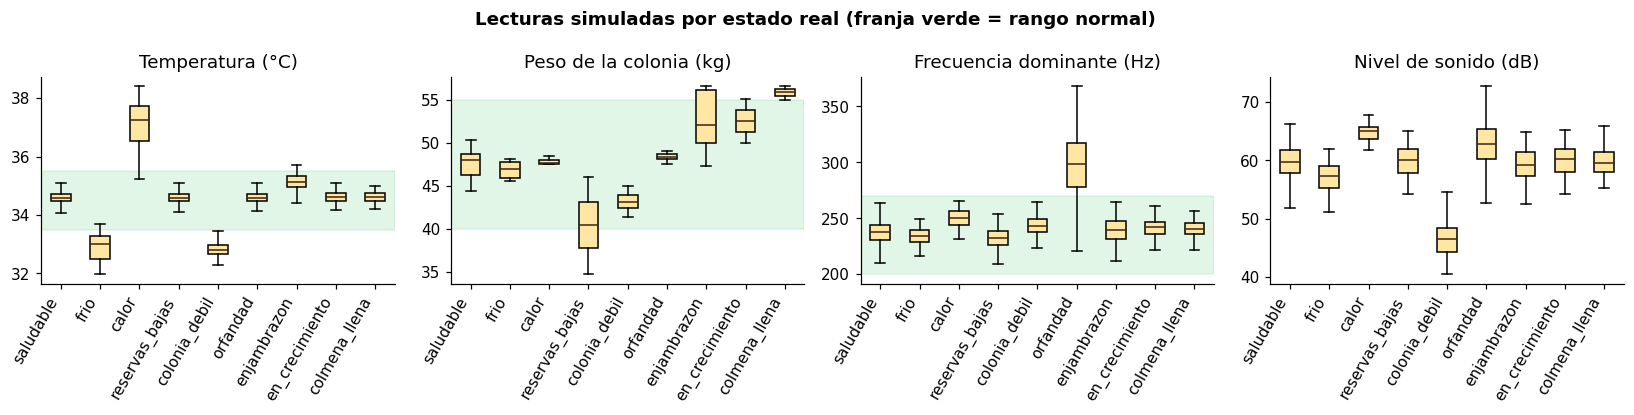

In [8]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, col, tit in zip(axs, ["temp_c", "peso_colonia_kg", "freq_hz", "nivel_db"], ["Temperatura (°C)", "Peso de la colonia (kg)", "Frecuencia dominante (Hz)", "Nivel de sonido (dB)"]):
    datos_box = [lecturas.loc[lecturas.estado_real == e, col] for e in orden]
    ax.boxplot(datos_box, showfliers=False, patch_artist=True, boxprops=dict(facecolor="#FFE7A3"), medianprops=dict(color="#3B2410"))
    ax.set_xticks(range(1, len(orden) + 1)); ax.set_xticklabels(orden, rotation=60, ha="right"); ax.set_title(tit)
axs[0].axhspan(*UMBRALES["temp_verde"], color=COLOR["verde"], alpha=.15)
axs[1].axhspan(UMBRALES["peso_verde_min"], UMBRALES["peso_lleno"], color=COLOR["verde"], alpha=.15)
axs[2].axhspan(*UMBRALES["freq_normal"], color=COLOR["verde"], alpha=.15)
fig.suptitle("Lecturas simuladas por estado real (franja verde = rango normal)", fontweight="bold")
fig.tight_layout(); fig.savefig(DIR_FIG / "fig01_lecturas_por_estado.png"); plt.show()

## 2. Indicadores y semáforo

Las lecturas crudas tienen ruido, así que primero se suavizan (mediana móvil), se descuenta la tara de las alzas y se calculan
cambios de peso. Con esos valores se encienden **12 indicadores** entre 0 y 1 (0 = normal, 0,5 = atención, 1 = alarma o aviso).
Una señal se confirma solo si se mantiene varias horas seguidas (persistencia), para no alarmar por una lectura suelta. La
caída brusca de peso es la excepción: se confirma de inmediato y se mantiene 24 h. Los **niveles** de peso (liviana, grande,
muy grande) y el **casi silencio** se evalúan con el promedio de 24 h, porque el peso y el zumbido suben y bajan cada día de
forma normal; con lecturas sueltas el semáforo cambiaría de color varias veces al día sin que pase nada. La alarma de
orfandad tiene **histéresis**: una vez confirmada se sostiene 6 h, para que el ruido del sensor no la apague y encienda.

El conjunto de los 12 indicadores es el **perfil de la colmena** en cada hora: lo que el recomendador compara con las acciones.

In [9]:
INDICADORES = ["temp_baja", "temp_alta", "peso_bajo", "peso_cae", "caida_brusca", "peso_grande", "gana_peso", "peso_alto",
               "sin_banda_250", "tonos_piping", "silencio", "irregular"]
NOMBRE_IND = {"temp_baja": "nido frío", "temp_alta": "nido caliente", "peso_bajo": "colonia liviana", "peso_cae": "pierde peso día a día",
              "caida_brusca": "caída brusca de peso", "peso_grande": "colonia grande (50–55 kg) y creciendo", "gana_peso": "buena recolección (gana peso)",
              "peso_alto": "colonia muy grande (> 55 kg)", "sin_banda_250": "zumbido sin la banda de 250 Hz",
              "tonos_piping": "tonos de 400–550 Hz", "silencio": "casi silencio", "irregular": "sonido irregular"}
ROJOS = ["temp_baja", "temp_alta", "peso_bajo", "caida_brusca", "sin_banda_250", "tonos_piping", "silencio", "peso_cae"]
AVISOS = ["peso_grande", "gana_peso", "peso_alto"]

def calcular_indicadores(df, U=UMBRALES):
    out = []
    for cid, g in df.groupby("colmena", sort=False):
        g = g.sort_values("fecha").copy()
        neto = g.peso_kg - U["tara_alza_kg"] * g.alzas                     # peso de la colonia sin alzas
        t3 = g.temp_c.rolling(3, min_periods=1).median()
        p3 = neto.rolling(3, min_periods=1).median()
        f6 = g.freq_hz.rolling(6, min_periods=1).median()
        f6std = g.freq_hz.where(g.freq_hz < U["freq_piping"][0]).rolling(6, min_periods=2).std()
        n3 = g.nivel_db.rolling(3, min_periods=1).median()
        n24 = g.nivel_db.rolling(24, min_periods=1).mean()                    # nivel promedio del día (sin el ciclo diario)
        n6std = g.nivel_db.rolling(6, min_periods=2).std()
        d2h = neto - neto.rolling(3, min_periods=1).max()                  # caída frente al máximo de las últimas 2 h
        m24 = p3.rolling(24, min_periods=1).mean()
        d7d = m24 - m24.shift(168)
        d3d = m24 - m24.shift(72)
        sube = ((m24 - m24.shift(24)) > 0.15).astype(float)
        baja = ((m24 - m24.shift(24)) < -0.15).astype(float)
        I = pd.DataFrame(index=g.index)
        I["temp_baja"] = np.select([t3 < U["temp_rojo_frio"], t3 < U["temp_verde"][0]], [1.0, 0.5], 0.0)
        I["temp_alta"] = np.select([t3 > U["temp_rojo_calor"], t3 > U["temp_verde"][1]], [1.0, 0.5], 0.0)
        I["peso_bajo"] = np.select([m24 < U["peso_rojo"], m24 < U["peso_verde_min"]], [1.0, 0.5], 0.0)   # niveles de peso con el promedio del día
        gradual_baja = baja.rolling(168, min_periods=1).mean() >= 0.7                # baja casi todos los días (no un solo escalón)
        I["peso_cae"] = np.select([gradual_baja & (d7d <= U["perdida_7d_rojo"]), gradual_baja & (d7d <= U["perdida_7d_amarillo"])], [1.0, 0.5], 0.0)
        I["gana_peso"] = ((sube.rolling(72, min_periods=1).mean() >= 0.66) & (d3d >= U["ganancia_3d"])).astype(float)
        # "colonia grande": promedio del día entre 50 y 55 kg Y ganando peso (así no parpadea por el ciclo diario del peso)
        I["peso_grande"] = (m24.between(U["peso_grande"], U["peso_lleno"]) & (I["gana_peso"] > 0)).astype(float)
        I["peso_alto"] = (m24 > U["peso_lleno"]).astype(float)
        piping = g.freq_hz.between(*U["freq_piping"]).astype(float)
        I["tonos_piping"] = piping.rolling(24, min_periods=1).max()                 # tonos de reina escuchados en las últimas 24 h
        fuera = ((f6 > U["freq_normal"][1]) & (f6 < U["freq_piping"][0])) | (f6 < U["freq_normal"][0])
        I["sin_banda_250"] = fuera.astype(float) * (I["tonos_piping"] == 0)
        I["silencio"] = np.select([n24 < U["nivel_silencio_rojo"], n24 < U["nivel_silencio_amarillo"]], [1.0, 0.5], 0.0)
        I["irregular"] = (((f6std > U["freq_irregular_std"]) | (n6std > U["nivel_irregular_std"])) * 0.5).astype(float)
        k = U["persistencia_h"]
        for c in ["sin_banda_250", "irregular"]:
            I[c] = I[c].rolling(k, min_periods=1).min()
        I["sin_banda_250"] = I["sin_banda_250"].rolling(6, min_periods=1).max()   # histéresis: la alarma confirmada se sostiene 6 h
        for c in ["temp_baja", "temp_alta"]:
            I[c] = I[c].rolling(U["persistencia_temp_h"], min_periods=1).min()
        I["caida_brusca"] = (d2h <= -U["caida_brusca_kg"]).astype(float).rolling(24, min_periods=1).max()
        I["temp_c_suav"], I["peso_colonia_suav"], I["peso_colonia_dia"], I["freq_suav"], I["nivel_suav"] = t3, p3, m24, f6, n3
        out.append(I)
    return df.join(pd.concat(out))

def semaforo(fila):
    """Rojo: algún indicador de alarma vale 1 · Amarillo: alguno vale 0,5 · Azul: solo avisos de manejo · Verde: nada."""
    if any(fila[c] >= 1 for c in ROJOS): return "rojo"
    if any(fila[c] >= 0.5 for c in INDICADORES if c not in AVISOS): return "amarillo"
    if any(fila[c] >= 1 for c in AVISOS): return "azul"
    return "verde"

datos = calcular_indicadores(lecturas)
datos["semaforo"] = datos.apply(semaforo, axis=1)
datos["semaforo"].value_counts()

semaforo
verde       2384
rojo        1348
azul         439
amarillo     149
Name: count, dtype: int64

Mapa del semáforo de todo el apiario, **hora por hora** (así lo vería el apicultor en la app). La línea punteada marca el
inicio de los datos de prueba (segunda quincena). Debajo, el conteo exacto de horas por color, que coincide con el mapa.

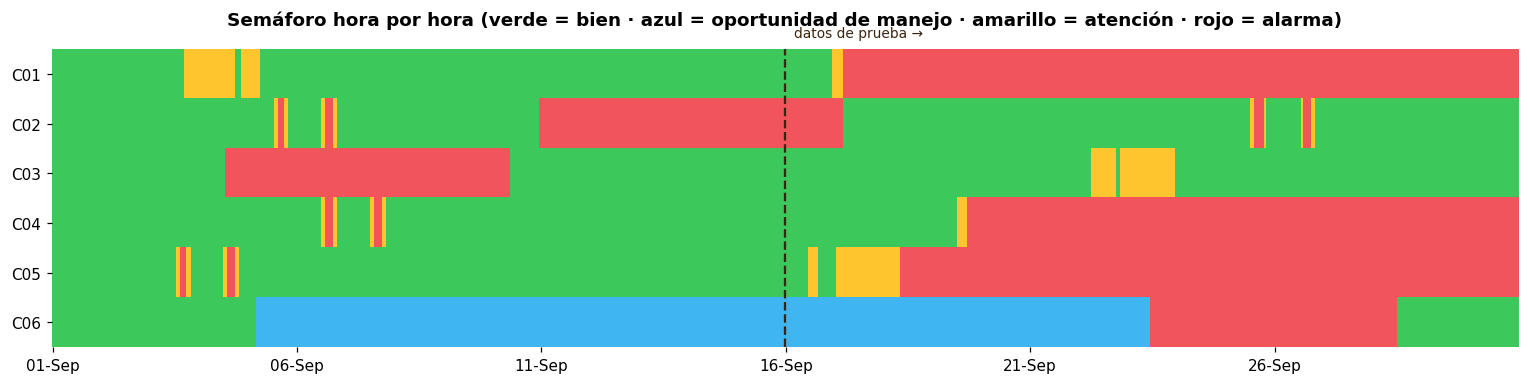

quincena 1ª quincena                    2ª quincena (prueba)                   
semaforo       verde azul amarillo rojo                verde azul amarillo rojo
colmena                                                                        
C01              326    0       34    0                   23    0        5  332
C02              224    0        8  128                  317    0        6   37
C03              220    0        0  140                  321    0       39    0
C04              344    0        8    8                   84    0        5  271
C05              345    0        8    7                   20    0       36  304
C06              100  260        0    0                   60  179        0  121

In [10]:
niv = {"verde": 0, "azul": 1, "amarillo": 2, "rojo": 3}
mapa = datos.assign(n=datos.semaforo.map(niv)).pivot(index="colmena", columns="fecha", values="n")
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.imshow(mapa.values, aspect="auto", cmap=ListedColormap([COLOR["verde"], COLOR["azul"], COLOR["amarillo"], COLOR["rojo"]]), vmin=0, vmax=3, interpolation="nearest")
ax.set_yticks(range(len(mapa.index))); ax.set_yticklabels(mapa.index)
ax.set_xticks(range(0, HORAS, 24 * 5)); ax.set_xticklabels([d.strftime("%d-%b") for d in mapa.columns[::24 * 5]])
ax.axvline(15 * 24 - 0.5, color="#3B2410", ls="--", lw=1.5); ax.text(15 * 24 + 4, -0.75, "datos de prueba →", fontsize=9, color="#3B2410")
ax.set_title("Semáforo hora por hora (verde = bien · azul = oportunidad de manejo · amarillo = atención · rojo = alarma)", fontweight="bold", pad=16)
for s in ax.spines.values(): s.set_visible(False)
fig.tight_layout(); fig.savefig(DIR_FIG / "fig02_semaforo_apiario.png"); plt.show()

horas_color = (datos.assign(quincena=np.where(datos.fecha < INICIO + pd.Timedelta(days=15), "1ª quincena", "2ª quincena (prueba)"))
               .pivot_table(index="colmena", columns=["quincena", "semaforo"], values="fecha", aggfunc="count", fill_value=0)
               .reindex(columns=["verde", "azul", "amarillo", "rojo"], level=1))
horas_color

## 3. Catálogo de acciones y recomendador basado en contenido

**Ítems a recomendar:** las 9 acciones que se hacen en el apiario (más "sin acción" cuando todo está en verde). Cada acción tiene
un **perfil de contenido**: cuánto atiende cada uno de los 12 indicadores (0 a 1), y un **requisito de manejo** (por ejemplo,
solo se puede *quitar alza* si la colmena tiene alzas, solo se *recolecta* si ya tiene dos, y solo se *alimenta* si tiene alimentador).

**Perfil del usuario (la colmena):** el vector de indicadores de la hora actual + su configuración de manejo (historial).

**Recomendación:**
1. Si hay alguna alarma en rojo, los avisos de manejo (colonia grande, buena recolección) se dejan para después.
2. Se descartan las acciones que no se pueden hacer con la configuración actual.
3. Se calcula la similitud coseno entre el perfil de la colmena y el de cada acción, se ordenan y se muestran las **3 mejores**
   (con similitud ≥ 0,30), cada una con su **explicación**. Si la colmena está en verde: "Sin acción".

In [11]:
ACCIONES = [
    # id, tipo, acción, perfil {indicador: peso}, requisito(alzas, trampa, alimentador)
    ("A0", "—", "Sin acción: seguir monitoreando", {}, lambda a, t, al: True),
    ("A1", "Revisar", "Revisar la colmena (estado y postura de la reina)",
     {"sin_banda_250": .9, "tonos_piping": .9, "caida_brusca": .8, "temp_baja": .7, "irregular": .6, "silencio": .6, "peso_cae": .3}, lambda a, t, al: True),
    ("A2", "Alimentar", "Alimentar", {"temp_alta": 1.0, "peso_cae": 1.0, "peso_bajo": .9, "silencio": .7}, lambda a, t, al: al),   # solo si hay alimentador
    ("A3", "Optimizar", "Poner alza", {"peso_alto": 1.0, "tonos_piping": .4, "gana_peso": .3}, lambda a, t, al: a < 2),
    ("A4", "Optimizar", "Quitar alza", {"peso_bajo": .7, "silencio": .7, "peso_cae": .4}, lambda a, t, al: a >= 1),
    ("A5", "Optimizar", "Poner trampa de polen", {"peso_grande": 1.0, "gana_peso": .8, "peso_alto": .3}, lambda a, t, al: not t),
    ("A6", "Optimizar", "Quitar trampa de polen", {"sin_banda_250": 1.0, "peso_bajo": .6, "silencio": .6, "peso_cae": .5}, lambda a, t, al: t),
    ("A7", "Optimizar", "Quitar alimentador", {"gana_peso": .9, "peso_alto": .7, "peso_grande": .6}, lambda a, t, al: al),
    ("A8", "Recolectar", "Recolectar la miel", {"peso_alto": 1.0, "gana_peso": .3}, lambda a, t, al: a >= 2),
    # sin "temp_alta": un pico de calor al mediodía no justifica poner alimentador
    ("A9", "Alimentar", "Poner alimentador", {"peso_cae": 1.0, "peso_bajo": .9, "silencio": .7}, lambda a, t, al: not al),
]
REQUISITO = {a: req for a, _, _, _, req in ACCIONES}
catalogo = pd.DataFrame([{"id": a, "tipo": tp, "accion": n, **{c: p.get(c, 0.0) for c in INDICADORES}} for a, tp, n, p, _ in ACCIONES]).set_index("id")
catalogo.to_csv(DIR_DATOS / "catalogo_acciones.csv")
catalogo

,tipo,accion,temp_baja,temp_alta,peso_bajo,peso_cae,caida_brusca,peso_grande,gana_peso,peso_alto,sin_banda_250,tonos_piping,silencio,irregular
id,,,,,,,,,,,,,,
A0,—,Sin acción: seguir monitoreando,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A1,Revisar,Revisar la colmena (estado y postura de la reina),0.7,0.0,0.0,0.3,0.8,0.0,0.0,0.0,0.9,0.9,0.6,0.6
A2,Alimentar,Alimentar,0.0,1.0,0.9,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.7,0.0
A3,Optimizar,Poner alza,0.0,0.0,0.0,0.0,0.0,0.0,0.3,1.0,0.0,0.4,0.0,0.0
A4,Optimizar,Quitar alza,0.0,0.0,0.7,0.4,0.0,0.0,0.0,0.0,0.0,0.0,0.7,0.0
A5,Optimizar,Poner trampa de polen,0.0,0.0,0.0,0.0,0.0,1.0,0.8,0.3,0.0,0.0,0.0,0.0
A6,Optimizar,Quitar trampa de polen,0.0,0.0,0.6,0.5,0.0,0.0,0.0,0.0,1.0,0.0,0.6,0.0
A7,Optimizar,Quitar alimentador,0.0,0.0,0.0,0.0,0.0,0.6,0.9,0.7,0.0,0.0,0.0,0.0
A8,Recolectar,Recolectar la miel,0.0,0.0,0.0,0.0,0.0,0.0,0.3,1.0,0.0,0.0,0.0,0.0


In [12]:
M = catalogo[INDICADORES].values                       # perfiles de contenido de las acciones (10 × 12)
NORM_M = np.linalg.norm(M, axis=1)
IDX_ROJOS = [INDICADORES.index(c) for c in ROJOS]
IDX_AVISOS = [INDICADORES.index(c) for c in AVISOS]

def priorizar(perfil):
    """Las alarmas tienen prioridad: si hay algún indicador en rojo, los avisos de manejo se dejan para después."""
    p = np.asarray(perfil, float).copy()
    if p[IDX_ROJOS].max() >= 1: p[IDX_AVISOS] = 0.0
    return p

def recomendar(perfil, alzas, trampa, alimentador, k=3, umbral=0.30):
    """perfil: vector de 12 indicadores + configuración de manejo. Devuelve lista de (id, similitud, explicación)."""
    p = priorizar(perfil)
    if p.sum() == 0:
        return [("A0", 1.0, "todos los indicadores en verde")]
    sim = np.nan_to_num((M @ p) / (NORM_M * np.linalg.norm(p) + 1e-12))
    posible = np.array([REQUISITO[a](alzas, trampa, alimentador) for a in catalogo.index])
    sim[~posible] = 0.0
    res = []
    for j in np.argsort(-np.round(sim, 3), kind="stable")[:k]:
        if sim[j] < umbral: break
        aporte = M[j] * p
        top = [NOMBRE_IND[INDICADORES[i]] for i in np.argsort(-aporte)[:2] if aporte[i] > 0]
        res.append((catalogo.index[j], float(sim[j]), " + ".join(top)))
    if not res and p[IDX_AVISOS].max() > 0 and p[IDX_ROJOS].max() == 0:
        return [("A0", 0.0, "el manejo ya está ajustado: seguir monitoreando")]
    if not res and p[INDICADORES.index("temp_alta")] > 0 and not alimentador:
        return [("A0", 0.0, "pico de calor sin alimentador: seguir monitoreando")]
    return res or [("A0", 0.0, "señales leves: seguir monitoreando")]

# Estado identificado: el prototipo de estado más parecido al perfil (también por similitud coseno)
PROTOTIPOS = {
    "frio": {"temp_baja": 1.0},
    "calor": {"temp_alta": 1.0},
    "reservas_bajas": {"peso_bajo": .8, "peso_cae": 1.0},
    "colonia_debil": {"silencio": 1.0, "temp_baja": .5, "peso_bajo": .5},
    "orfandad": {"sin_banda_250": 1.0, "irregular": .4},
    "enjambrazon": {"tonos_piping": 1.0, "caida_brusca": 1.0},
    "en_crecimiento": {"peso_grande": 1.0, "gana_peso": 1.0},
    "colmena_llena": {"peso_alto": 1.0, "gana_peso": .3},
}
P = np.array([[PROTOTIPOS[s].get(c, 0.0) for c in INDICADORES] for s in PROTOTIPOS])

def inferir_estado(perfil):
    p = priorizar(perfil)
    if p.sum() == 0: return "saludable"
    sim = (P @ p) / (np.linalg.norm(P, axis=1) * np.linalg.norm(p) + 1e-12)
    return list(PROTOTIPOS)[int(np.argmax(sim))]

perfiles = datos[INDICADORES].values
recs = [recomendar(p, a, t, al) for p, a, t, al in zip(perfiles, datos.alzas, datos.trampa_polen, datos.alimentador)]
datos["estado_inferido"] = [inferir_estado(p) for p in perfiles]
datos["recomendaciones"] = [[r[0] for r in rr] for rr in recs]
datos["explicaciones"] = [[r[2] for r in rr] for rr in recs]
datos["similitudes"] = [[round(r[1], 2) for r in rr] for rr in recs]
datos[["colmena", "fecha", "alzas", "trampa_polen", "alimentador", "semaforo", "estado_inferido", "recomendaciones", "similitudes"]].sample(6, random_state=1)

,colmena,fecha,alzas,trampa_polen,alimentador,semaforo,estado_inferido,recomendaciones,similitudes
2756,C04,2026-09-25 20:00:00,1,True,True,rojo,orfandad,"[A6, A1]","[0.64, 0.57]"
2815,C04,2026-09-28 07:00:00,1,True,True,rojo,orfandad,"[A6, A1]","[0.64, 0.57]"
1781,C03,2026-09-15 05:00:00,1,False,False,verde,saludable,[A0],[1.0]
3774,C06,2026-09-08 06:00:00,1,False,True,azul,en_crecimiento,"[A5, A7]","[0.97, 0.82]"
2388,C04,2026-09-10 12:00:00,1,True,True,verde,saludable,[A0],[1.0]
2662,C04,2026-09-21 22:00:00,1,True,True,rojo,orfandad,"[A6, A1]","[0.71, 0.48]"


## 4. Demostración con un perfil específico: colmena **C04**

La C04 es una colmena fuerte (≈ 49 kg de colonia) con **1 alza, trampa de polen y alimentador**. Vive dos situaciones: una
**ola de calor** los días 6 y 7 de septiembre y, desde el 18, la **pérdida de la reina** (orfandad). Veamos cómo el sistema
procesa sus lecturas y qué recomienda.

In [13]:
c04 = datos[datos.colmena == "C04"].set_index("fecha")
ev_c04 = eventos[eventos.colmena == "C04"]
ev_c04

,colmena,evento,inicio,fin
9,C04,calor,2026-09-06 00:00:00,2026-09-07 23:00:00
10,C04,orfandad,2026-09-18 17:00:00,2026-09-30 23:00:00


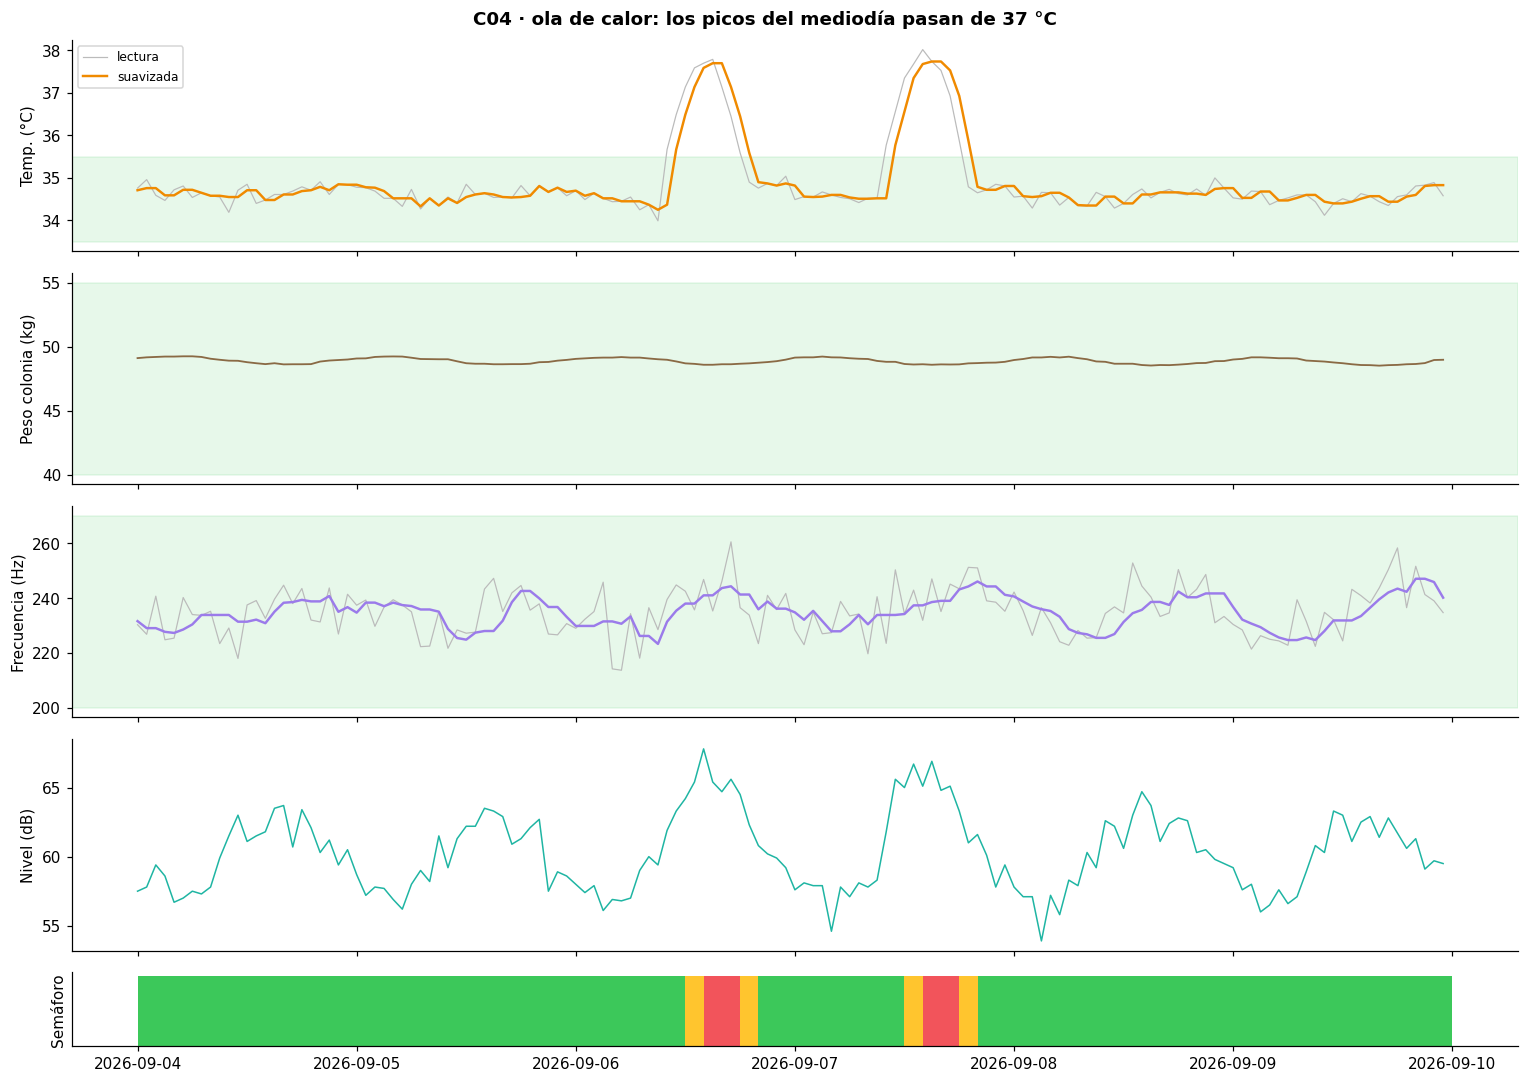

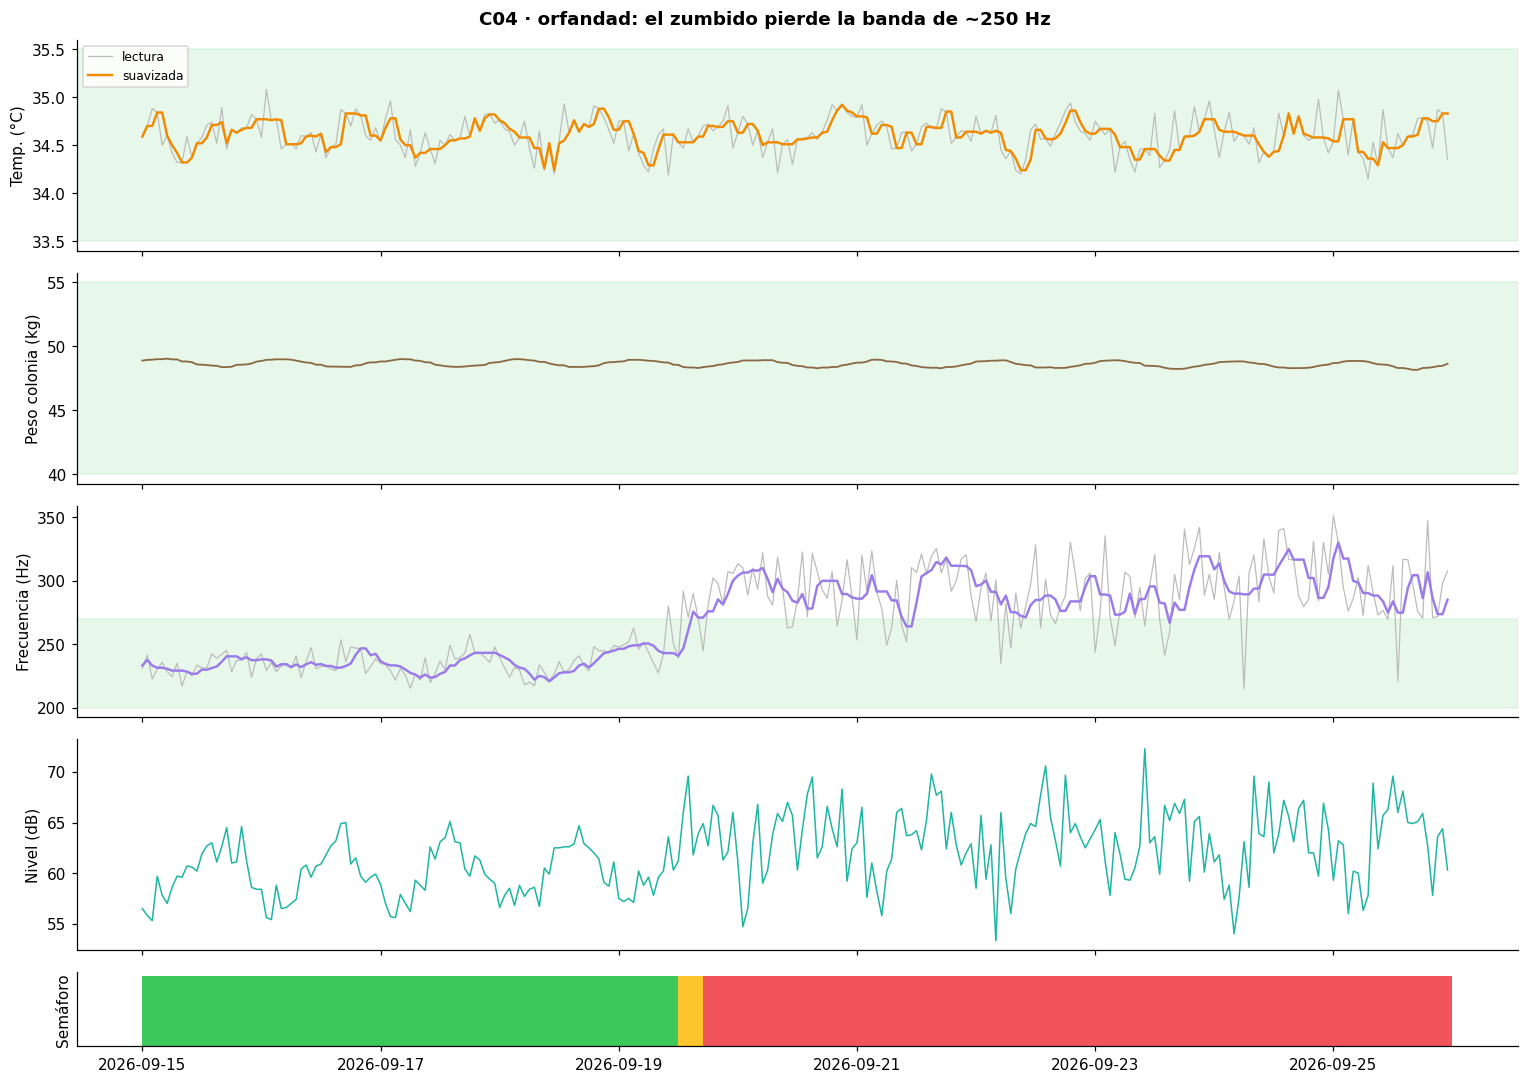

In [14]:
def panel_colmena(df, desde, hasta, titulo, archivo):
    d = df.loc[desde:hasta]
    fig, axs = plt.subplots(5, 1, figsize=(14, 10), sharex=True, gridspec_kw=dict(height_ratios=[2, 2, 2, 2, .7]))
    axs[0].plot(d.index, d.temp_c, color="#bbb", lw=.8, label="lectura"); axs[0].plot(d.index, d.temp_c_suav, color="#F08A00", lw=1.6, label="suavizada")
    axs[0].axhspan(*UMBRALES["temp_verde"], color=COLOR["verde"], alpha=.12); axs[0].set_ylabel("Temp. (°C)"); axs[0].legend(loc="upper left", fontsize=8)
    axs[1].plot(d.index, d.peso_colonia_suav, color="#8A6A45", lw=1.2); axs[1].axhspan(UMBRALES["peso_verde_min"], UMBRALES["peso_lleno"], color=COLOR["verde"], alpha=.12)
    axs[1].set_ylabel("Peso colonia (kg)")
    axs[2].plot(d.index, d.freq_hz, color="#bbb", lw=.8); axs[2].plot(d.index, d.freq_suav, color="#9B7BEA", lw=1.6)
    axs[2].axhspan(*UMBRALES["freq_normal"], color=COLOR["verde"], alpha=.12); axs[2].set_ylabel("Frecuencia (Hz)")
    axs[3].plot(d.index, d.nivel_db, color="#1FB5A3", lw=1); axs[3].set_ylabel("Nivel (dB)")
    axs[4].bar(d.index, 1, width=1 / 24, color=d.semaforo.map(COLOR), align="edge"); axs[4].set_yticks([]); axs[4].set_ylabel("Semáforo")
    fig.suptitle(titulo, fontweight="bold"); fig.tight_layout(); fig.savefig(DIR_FIG / archivo); plt.show()

panel_colmena(c04, "2026-09-04", "2026-09-09", "C04 · ola de calor: los picos del mediodía pasan de 37 °C", "fig03_demo_c04_calor.png")
panel_colmena(c04, "2026-09-15", "2026-09-25", "C04 · orfandad: el zumbido pierde la banda de ~250 Hz", "fig04_demo_c04_orfandad.png")

**Qué recomienda el sistema en momentos clave de la C04** (perfil = indicadores activos + configuración de manejo):

In [15]:
def ficha(cid, fecha):
    f = datos[(datos.colmena == cid) & (datos.fecha == pd.Timestamp(fecha))].iloc[0]
    activos = {NOMBRE_IND[c]: float(f[c]) for c in INDICADORES if f[c] > 0}
    print(f"── {cid} · {fecha} ──  semáforo: {f.semaforo.upper()} · estado identificado: {f.estado_inferido} · estado real: {f.estado_real}")
    print(f"   lecturas: {f.temp_c:.1f} °C · colonia {f.peso_colonia_suav:.1f} kg · {f.freq_hz:.0f} Hz · {f.nivel_db:.0f} dB")
    print(f"   manejo: {f.alzas} alza(s) · trampa de polen: {'sí' if f.trampa_polen else 'no'} · alimentador: {'sí' if f.alimentador else 'no'}")
    print(f"   perfil (indicadores activos): {activos if activos else 'ninguno'}")
    for i, (a, s, e) in enumerate(zip(f.recomendaciones, f.similitudes, f.explicaciones), 1):
        print(f"   {i}. [{catalogo.loc[a, 'tipo']}] {catalogo.loc[a, 'accion']}  (similitud {s:.2f}) ← {e}")
    print()

h_orf = ev_c04.loc[ev_c04.evento == "orfandad", "inicio"].iloc[0]
primer_aviso = c04.loc[h_orf:].query("estado_inferido == 'orfandad'").index[0]
primer_rojo = c04.loc[h_orf:].query("estado_inferido == 'orfandad' and semaforo == 'rojo'").index[0]
for momento in ["2026-09-03 10:00", "2026-09-06 15:00", "2026-09-06 23:00", str(h_orf), str(primer_aviso), str(primer_rojo)]:
    ficha("C04", momento)
print(f"La orfandad empezó {h_orf}: aviso amarillo {primer_aviso} ({(primer_aviso - h_orf) / pd.Timedelta(hours=1):.0f} h) "
      f"y alarma roja {primer_rojo} ({(primer_rojo - h_orf) / pd.Timedelta(hours=1):.0f} h).")

── C04 · 2026-09-03 10:00 ──  semáforo: VERDE · estado identificado: saludable · estado real: saludable
   lecturas: 34.5 °C · colonia 48.9 kg · 222 Hz · 59 dB
   manejo: 1 alza(s) · trampa de polen: sí · alimentador: sí
   perfil (indicadores activos): ninguno
   1. [—] Sin acción: seguir monitoreando  (similitud 1.00) ← todos los indicadores en verde

── C04 · 2026-09-06 15:00 ──  semáforo: ROJO · estado identificado: calor · estado real: calor
   lecturas: 37.8 °C · colonia 48.6 kg · 235 Hz · 65 dB
   manejo: 1 alza(s) · trampa de polen: sí · alimentador: sí
   perfil (indicadores activos): {'nido caliente': 1.0}
   1. [Alimentar] Alimentar  (similitud 0.55) ← nido caliente

── C04 · 2026-09-06 23:00 ──  semáforo: VERDE · estado identificado: saludable · estado real: saludable
   lecturas: 35.0 °C · colonia 49.0 kg · 242 Hz · 59 dB
   manejo: 1 alza(s) · trampa de polen: sí · alimentador: sí
   perfil (indicadores activos): ninguno
   1. [—] Sin acción: seguir monitoreando  (similit

**Cómo se procesa el perfil (paso a paso, en la primera alarma roja de orfandad):**

In [16]:
f = datos[(datos.colmena == "C04") & (datos.fecha == primer_rojo)].iloc[0]
perfil = pd.Series(priorizar(f[INDICADORES].astype(float).values), index=INDICADORES)
sims = pd.Series((M @ perfil.values) / (NORM_M * np.linalg.norm(perfil.values) + 1e-12), index=catalogo.index)
posible = pd.Series([REQUISITO[a](f.alzas, f.trampa_polen, f.alimentador) for a in catalogo.index], index=catalogo.index)
tabla = catalogo[["tipo", "accion"]].assign(similitud=sims.round(3), se_puede_hacer=posible).sort_values("similitud", ascending=False)
print("Perfil de la colmena (12 indicadores):"); print(perfil.to_string()); print()
tabla

Perfil de la colmena (12 indicadores):
temp_baja        0.0
temp_alta        0.0
peso_bajo        0.0
peso_cae         0.0
caida_brusca     0.0
peso_grande      0.0
gana_peso        0.0
peso_alto        0.0
sin_banda_250    1.0
tonos_piping     0.0
silencio         0.0
irregular        0.5



,tipo,accion,similitud,se_puede_hacer
id,,,,
A6,Optimizar,Quitar trampa de polen,0.637,True
A1,Revisar,Revisar la colmena (estado y postura de la reina),0.569,True
A0,—,Sin acción: seguir monitoreando,0.000,True
A2,Alimentar,Alimentar,0.000,True
A4,Optimizar,Quitar alza,0.000,True
A3,Optimizar,Poner alza,0.000,True
A5,Optimizar,Poner trampa de polen,0.000,False
A7,Optimizar,Quitar alimentador,0.000,True
A8,Recolectar,Recolectar la miel,0.000,False


**Otra demostración: C06, la colmena que crece.** Muestra el ciclo de *Optimizar* y *Recolectar* según su bitácora de manejo:

In [17]:
for momento in ["2026-09-06 12:00", "2026-09-12 12:00", "2026-09-18 14:00", "2026-09-20 12:00"]:
    ficha("C06", momento)

── C06 · 2026-09-06 12:00 ──  semáforo: AZUL · estado identificado: en_crecimiento · estado real: en_crecimiento
   lecturas: 34.7 °C · colonia 50.5 kg · 228 Hz · 60 dB
   manejo: 1 alza(s) · trampa de polen: no · alimentador: sí
   perfil (indicadores activos): {'colonia grande (50–55 kg) y creciendo': 1.0, 'buena recolección (gana peso)': 1.0}
   1. [Optimizar] Poner trampa de polen  (similitud 0.97) ← colonia grande (50–55 kg) y creciendo + buena recolección (gana peso)
   2. [Optimizar] Quitar alimentador  (similitud 0.82) ← buena recolección (gana peso) + colonia grande (50–55 kg) y creciendo

── C06 · 2026-09-12 12:00 ──  semáforo: AZUL · estado identificado: en_crecimiento · estado real: en_crecimiento
   lecturas: 34.6 °C · colonia 52.7 kg · 245 Hz · 63 dB
   manejo: 1 alza(s) · trampa de polen: sí · alimentador: no
   perfil (indicadores activos): {'colonia grande (50–55 kg) y creciendo': 1.0, 'buena recolección (gana peso)': 1.0}
   1. [—] Sin acción: seguir monitoreando  (si

## 5. Evaluación

La evaluación usa los **datos de prueba simulados**, donde sabemos qué le pasaba realmente a cada colmena en cada hora
(*estado_real*). Para cada estado se definió, con las prácticas del apiario, qué acciones son las **correctas**, teniendo en
cuenta la configuración de la colmena (por ejemplo, con dos alzas lo correcto es recolectar, no poner otra alza). Se compara
con un **sistema de referencia por popularidad**, que siempre recomienda las 3 acciones más frecuentes del historial, sin mirar
los sensores. La **primera quincena** sirve de historial para esa referencia y la **segunda quincena** son los datos de prueba.
**Precision@3** = acciones correctas entre las 3 primeras recomendaciones ÷ 3 (definición estándar: si el sistema recomienda
menos de 3 acciones, los puestos vacíos cuentan como no acertados).

In [18]:
def correctas(estado, alzas, trampa, alimentador):
    """Acciones correctas según la práctica del apiario."""
    alimentar = {"A2"} if alimentador else {"A9"}          # sin alimentador, primero hay que ponerlo
    if estado == "saludable": return {"A0"}
    if estado == "frio": return {"A1"}
    if estado == "calor": return {"A2"} if alimentador else {"A0"}   # un pico de calor al mediodía no justifica poner alimentador
    if estado == "reservas_bajas": return alimentar | ({"A6"} if trampa else set()) | ({"A4"} if alzas >= 1 else set())
    if estado == "colonia_debil": return {"A1"} | alimentar | ({"A4"} if alzas >= 1 else set()) | ({"A6"} if trampa else set())
    if estado == "orfandad": return {"A1"} | ({"A6"} if trampa else set())
    if estado == "enjambrazon": return {"A1"} | ({"A3"} if alzas < 2 else set())
    if estado == "en_crecimiento": return (({"A5"} if not trampa else set()) | ({"A7"} if alimentador else set())) or {"A0"}
    if estado == "colmena_llena": return ({"A3"} if alzas < 2 else {"A8"}) | ({"A7"} if alimentador else set()) | ({"A5"} if not trampa else set())
    raise ValueError(estado)

datos["correctas"] = [correctas(e, a, t, al) for e, a, t, al in zip(datos.estado_real, datos.alzas, datos.trampa_polen, datos.alimentador)]

def metricas(recs, rels, k=3):
    p, r, h = [], [], []
    for rec, rel in zip(recs, rels):
        top = rec[:k]; aciertos = len(set(top) & rel)
        p.append(aciertos / k); r.append(aciertos / len(rel)); h.append(aciertos > 0)
    return np.mean(p), np.mean(r), np.mean(h)

hist = datos[datos.fecha < INICIO + pd.Timedelta(days=15)]
popular = list(pd.Series([a for rel in hist.correctas for a in rel]).value_counts().index[:3])
print("Recomendación fija por popularidad:", [catalogo.loc[a, "accion"] for a in popular])

prueba = datos[datos.fecha >= INICIO + pd.Timedelta(days=15)]   # segunda quincena = datos de prueba
filas = []
for nombre, sub in [("Todas las horas", prueba), ("Solo horas con problema u oportunidad", prueba[prueba.estado_real != "saludable"])]:
    for sis, recs_ in [("Basado en contenido", sub.recomendaciones), ("Popularidad", [popular] * len(sub))]:
        p_, r_, h_ = metricas(list(recs_), sub.correctas)
        filas.append(dict(conjunto=nombre, sistema=sis, **{"Precision@3": p_, "Recall@3": r_, "Acierto@3": h_}))
tabla_prec = pd.DataFrame(filas).round(3)
tabla_prec

Recomendación fija por popularidad: ['Sin acción: seguir monitoreando', 'Revisar la colmena (estado y postura de la reina)', 'Quitar trampa de polen']


,conjunto,sistema,Precision@3,Recall@3,Acierto@3
0,Todas las horas,Basado en contenido,0.562,0.945,0.952
1,Todas las horas,Popularidad,0.362,0.729,0.950
2,Solo horas con problema u oportunidad,Basado en contenido,0.687,0.917,0.927
3,Solo horas con problema u oportunidad,Popularidad,0.378,0.582,0.923


**Precisión por estado** (sistema basado en contenido, datos de prueba):

In [19]:
por_estado = []
for e, sub in prueba.groupby("estado_real"):
    p_, r_, h_ = metricas(list(sub.recomendaciones), sub.correctas)
    por_estado.append(dict(estado=e, horas=len(sub), **{"Precision@3": p_, "Recall@3": r_, "Acierto@3": h_},
                           estado_bien_identificado=(sub.estado_inferido == e).mean()))
por_estado = pd.DataFrame(por_estado).set_index("estado").reindex([o for o in orden if o in prueba.estado_real.unique()]).round(3)
por_estado

,horas,Precision@3,Recall@3,Acierto@3,estado_bien_identificado
estado,,,,,
saludable,759,0.332,0.997,0.997,0.995
frio,41,0.309,0.927,0.927,0.927
calor,18,0.333,1.000,1.000,0.722
reservas_bajas,360,0.936,0.936,0.936,0.936
colonia_debil,357,0.919,0.919,0.952,0.936
orfandad,326,0.588,0.925,0.933,0.933
enjambrazon,144,0.278,0.833,0.833,0.833
en_crecimiento,47,0.333,1.000,1.000,1.000
colmena_llena,108,0.293,0.880,0.880,0.880


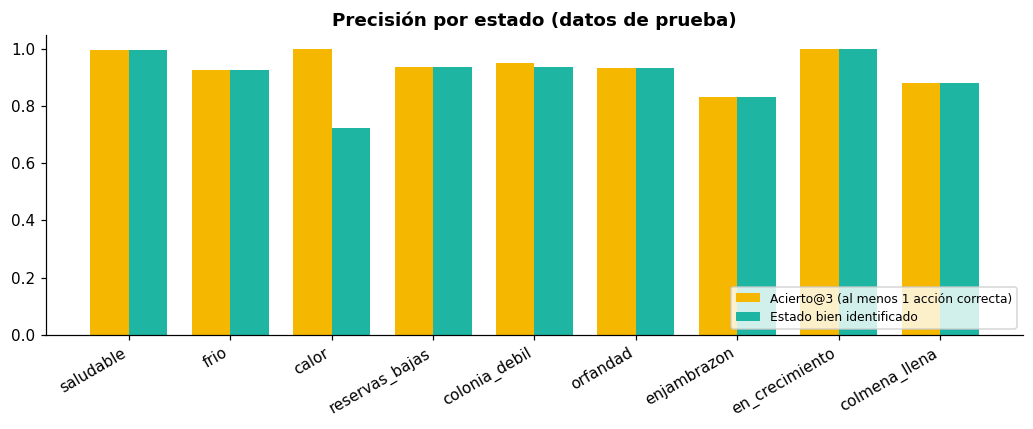

In [20]:
fig, ax = plt.subplots(figsize=(9.5, 4))
x = np.arange(len(por_estado)); w = .38
ax.bar(x - w / 2, por_estado["Acierto@3"], w, color="#F5B700", label="Acierto@3 (al menos 1 acción correcta)")
ax.bar(x + w / 2, por_estado["estado_bien_identificado"], w, color="#1FB5A3", label="Estado bien identificado")
ax.set_xticks(x); ax.set_xticklabels(por_estado.index, rotation=30, ha="right"); ax.set_ylim(0, 1.05); ax.legend(fontsize=8, loc="lower right")
ax.set_title("Precisión por estado (datos de prueba)", fontweight="bold"); fig.tight_layout(); fig.savefig(DIR_FIG / "fig05_precision_por_estado.png"); plt.show()

**Matriz de confusión del estado identificado** (filas = estado real, columnas = estado que identificó el sistema; % por fila):

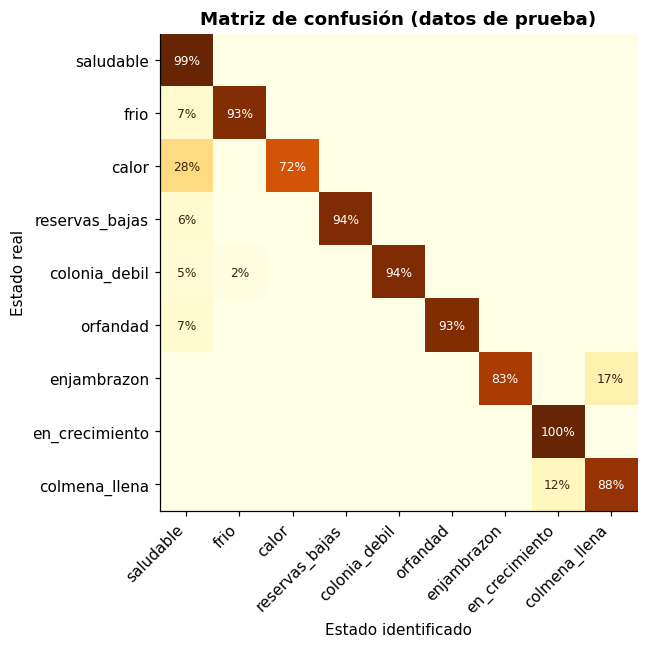

In [21]:
conf = pd.crosstab(prueba.estado_real, prueba.estado_inferido, normalize="index").reindex(index=orden, columns=orden, fill_value=0)
conf = conf.loc[[o for o in orden if o in prueba.estado_real.unique()]]
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(conf.values, cmap="YlOrBr", vmin=0, vmax=1)
ax.set_xticks(range(len(conf.columns))); ax.set_xticklabels(conf.columns, rotation=45, ha="right"); ax.set_yticks(range(len(conf.index))); ax.set_yticklabels(conf.index)
for i in range(conf.shape[0]):
    for j in range(conf.shape[1]):
        v = conf.values[i, j]
        if v >= .01: ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > .6 else "#3B2410")
ax.set_xlabel("Estado identificado"); ax.set_ylabel("Estado real"); ax.set_title("Matriz de confusión (datos de prueba)", fontweight="bold")
fig.tight_layout(); fig.savefig(DIR_FIG / "fig06_matriz_confusion.png"); plt.show()

**Anticipación y falsas alarmas.** Para cada evento, ¿cuántas horas tardó el sistema en identificarlo desde que el problema
está presente? Para la enjambrazón interesa además con cuánta **anticipación** avisó antes de que saliera el enjambre. Y en las
horas sanas, ¿cuántas veces encendió amarillo o rojo sin motivo?

In [22]:
det = []
for _, ev in eventos[~eventos.evento.str.startswith(("salida", "bitacora"))].iterrows():
    nombre_estado = "en_crecimiento" if ev.evento == "flujo_nectar" else ev.evento
    g = datos[(datos.colmena == ev.colmena) & (datos.fecha >= ev.inicio) & (datos.fecha <= ev.fin + pd.Timedelta(hours=24))]
    presente = g[g.estado_real == nombre_estado].fecha
    if presente.empty: continue
    t0 = presente.iloc[0]
    hit = g[(g.estado_inferido == nombre_estado) & (g.fecha >= t0)]
    fila = dict(colmena=ev.colmena, evento=nombre_estado, problema_presente_desde=t0,
                horas_hasta_detectar=(hit.fecha.iloc[0] - t0) / pd.Timedelta(hours=1) if len(hit) else np.nan)
    if ev.evento == "enjambrazon":
        salida = eventos[(eventos.colmena == ev.colmena) & (eventos.evento == "salida_enjambre")].inicio.iloc[0]
        fila["horas_de_anticipacion_a_la_salida"] = (salida - hit.fecha.iloc[0]) / pd.Timedelta(hours=1) if len(hit) else np.nan
    det.append(fila)
deteccion = pd.DataFrame(det)
deteccion

,colmena,evento,problema_presente_desde,horas_hasta_detectar,horas_de_anticipacion_a_la_salida
0,C01,frio,2026-09-03 12:00:00,5.0,NaN
1,C01,reservas_bajas,2026-09-11 07:00:00,136.0,NaN
2,C02,calor,2026-09-05 10:00:00,3.0,NaN
3,C02,orfandad,2026-09-10 07:00:00,16.0,NaN
4,C02,calor,2026-09-25 10:00:00,2.0,NaN
5,C03,enjambrazon,2026-09-04 08:00:00,5.0,115.0
6,C03,frio,2026-09-22 05:00:00,1.0,NaN
7,C04,calor,2026-09-06 11:00:00,1.0,NaN
8,C04,orfandad,2026-09-18 17:00:00,19.0,NaN
9,C05,calor,2026-09-03 11:00:00,2.0,NaN


In [23]:
sanas = datos[datos.estado_real == "saludable"]
print(f"Falsas alarmas (amarillo o rojo en horas sanas), todo el apiario: {(sanas.semaforo.isin(['amarillo', 'rojo'])).mean():.1%}")
(sanas.groupby("colmena").semaforo.apply(lambda s: s.isin(["amarillo", "rojo"]).mean()) * 100).round(2).rename("falsas_alarmas_%").to_frame().T

Falsas alarmas (amarillo o rojo en horas sanas), todo el apiario: 0.6%


colmena,C01,C02,C03,C04,C05,C06
falsas_alarmas_%,0.49,0.78,0.37,0.73,0.86,0.64


**Cobertura.** ¿Qué parte del catálogo llega a recomendarse y qué situaciones quedan fuera?

In [24]:
usadas = pd.Series([a for rr in datos.recomendaciones for a in rr]).value_counts()
print(f"Acciones del catálogo recomendadas al menos una vez: {usadas.index.nunique()} de {len(catalogo)} ({usadas.index.nunique() / len(catalogo):.0%})")
print(f"Horas con al menos una recomendación: {(datos.recomendaciones.str.len() > 0).mean():.0%}")
print(f"Estados que el sistema puede identificar: {len(PROTOTIPOS) + 1} (incluye 'saludable')")
frec = (usadas / usadas.sum() * 100).rename("% de recomendaciones").to_frame().join(catalogo[["tipo", "accion"]])
frec.round(1)

Acciones del catálogo recomendadas al menos una vez: 10 de 10 (100%)
Horas con al menos una recomendación: 100%
Estados que el sistema puede identificar: 9 (incluye 'saludable')


,% de recomendaciones,tipo,accion
A0,42.7,—,Sin acción: seguir monitoreando
A1,17.8,Revisar,Revisar la colmena (estado y postura de la reina)
A4,10.9,Optimizar,Quitar alza
A6,10.4,Optimizar,Quitar trampa de polen
A2,5.5,Alimentar,Alimentar
A9,5.5,Alimentar,Poner alimentador
A3,2.2,Optimizar,Poner alza
A7,1.7,Optimizar,Quitar alimentador
A5,1.7,Optimizar,Poner trampa de polen
A8,1.6,Recolectar,Recolectar la miel


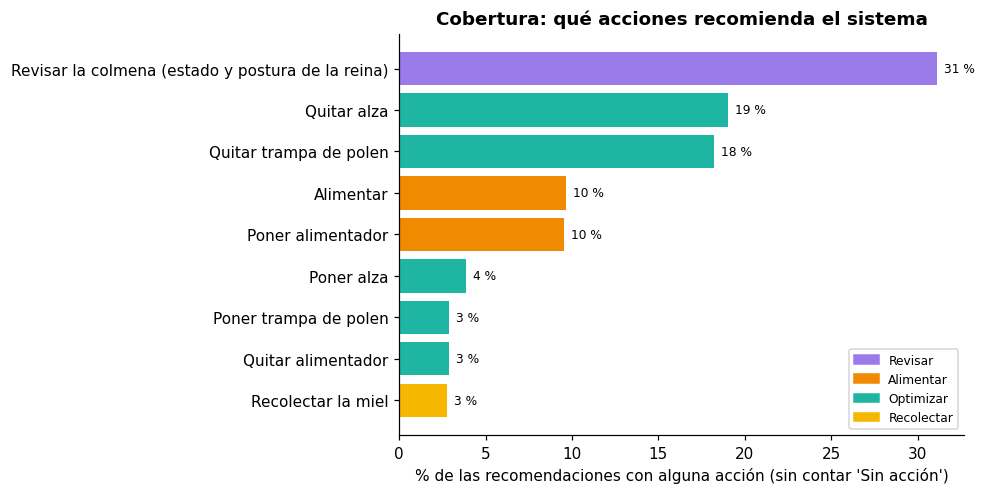

In [25]:
from matplotlib.patches import Patch
frec_sin = frec.drop(index="A0", errors="ignore").copy()
frec_sin["% de recomendaciones"] = frec_sin["% de recomendaciones"] / frec_sin["% de recomendaciones"].sum() * 100
frec_sin = frec_sin.sort_values("% de recomendaciones")
colores_tipo = {"Revisar": "#9B7BEA", "Alimentar": "#F08A00", "Optimizar": "#1FB5A3", "Recolectar": "#F5B700"}
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(frec_sin.accion, frec_sin["% de recomendaciones"], color=frec_sin.tipo.map(colores_tipo))
for y, v in enumerate(frec_sin["% de recomendaciones"]): ax.text(v + .4, y, f"{v:.0f} %", va="center", fontsize=8)
ax.legend(handles=[Patch(color=c, label=t) for t, c in colores_tipo.items()], fontsize=8, loc="lower right")
ax.set_xlabel("% de las recomendaciones con alguna acción (sin contar 'Sin acción')")
ax.set_title("Cobertura: qué acciones recomienda el sistema", fontweight="bold"); fig.tight_layout(); fig.savefig(DIR_FIG / "fig07_cobertura_acciones.png"); plt.show()

**Utilidad para la toma de decisiones.**

1. **Revisiones dirigidas.** Hoy se revisa todo el apiario cada semana. Con el sistema, solo se abre la colmena la semana en
   que recomienda *Revisar*:

In [26]:
sem = datos.assign(semana=datos.fecha.dt.isocalendar().week)
rutina = sem.groupby(["colmena", "semana"]).size().shape[0]
dirigidas = sem[sem.recomendaciones.apply(lambda r: "A1" in r)].groupby(["colmena", "semana"]).size().shape[0]
print(f"Revisiones con la rutina semanal: {rutina} · revisiones que pide el sistema: {dirigidas} "
      f"→ {1 - dirigidas / rutina:.0%} menos aperturas, y cada una con un motivo.")

Revisiones con la rutina semanal: 30 · revisiones que pide el sistema: 14 → 53% menos aperturas, y cada una con un motivo.


2. **¿A qué colmena ir primero?** Resumen de las horas en cada color durante **todo el mes** (las mismas del mapa), y por
   separado la segunda quincena, que es la situación más reciente:

In [27]:
def resumen_prioridad(df):
    return (df.assign(rojo=df.semaforo.eq("rojo"), amarillo=df.semaforo.eq("amarillo"), azul=df.semaforo.eq("azul"), verde=df.semaforo.eq("verde"))
              .groupby("colmena").agg(horas_rojo=("rojo", "sum"), horas_amarillo=("amarillo", "sum"), horas_azul=("azul", "sum"), horas_verde=("verde", "sum"),
                                      estado_mas_frecuente=("estado_inferido", lambda s: s[s != "saludable"].mode().iloc[0] if (s != "saludable").any() else "saludable"),
                                      accion_principal=("recomendaciones", lambda s: catalogo.loc[pd.Series([r[0] for r in s if r and r[0] != "A0"] or ["A0"]).mode().iloc[0], "accion"]))
              .sort_values(["horas_rojo", "horas_amarillo", "horas_azul"], ascending=False))

prior = resumen_prioridad(datos)
prior_reciente = resumen_prioridad(prueba)
print("Todo el mes (1–30 sep):"); display(prior)
print("Segunda quincena (16–30 sep):"); display(prior_reciente)

Todo el mes (1–30 sep):


,horas_rojo,horas_amarillo,horas_azul,horas_verde,estado_mas_frecuente,accion_principal
colmena,,,,,,
C01,332,39,0,349,reservas_bajas,Poner alimentador
C05,311,44,0,365,colonia_debil,Quitar alza
C04,279,13,0,428,orfandad,Quitar trampa de polen
C02,165,14,0,541,orfandad,Revisar la colmena (estado y postura de la reina)
C03,140,39,0,541,enjambrazon,Revisar la colmena (estado y postura de la reina)
C06,121,0,439,160,en_crecimiento,Revisar la colmena (estado y postura de la reina)


Segunda quincena (16–30 sep):


,horas_rojo,horas_amarillo,horas_azul,horas_verde,estado_mas_frecuente,accion_principal
colmena,,,,,,
C01,332,5,0,23,reservas_bajas,Poner alimentador
C05,304,36,0,20,colonia_debil,Quitar alza
C04,271,5,0,84,orfandad,Quitar trampa de polen
C06,121,0,179,60,enjambrazon,Revisar la colmena (estado y postura de la reina)
C02,37,6,0,317,orfandad,Revisar la colmena (estado y postura de la reina)
C03,0,39,0,321,frio,Revisar la colmena (estado y postura de la reina)


In [28]:
tabla_prec.to_csv(DIR_DATOS / "resultados_precision.csv", index=False)
por_estado.to_csv(DIR_DATOS / "resultados_por_estado.csv")
deteccion.to_csv(DIR_DATOS / "resultados_deteccion.csv", index=False)
prior.assign(periodo="1-30 sep").reset_index().to_csv(DIR_DATOS / "resultados_prioridad_colmenas.csv", index=False)
prior_reciente.assign(periodo="16-30 sep").reset_index().to_csv(DIR_DATOS / "resultados_prioridad_colmenas.csv", mode="a", header=False, index=False)
horas_color.to_csv(DIR_DATOS / "horas_por_color_semaforo.csv")
(datos.drop(columns=["correctas"]).assign(recomendaciones=datos.recomendaciones.str.join("|"), explicaciones=datos.explicaciones.str.join("|"),
                                            similitudes=datos.similitudes.astype(str))
      .to_csv(DIR_DATOS / "recomendaciones_por_hora.csv", index=False))
print("Resultados guardados en", DIR_DATOS.resolve())

Resultados guardados en C:\Users\Oscar Cardozo\OneDrive\Documents\Universidad\Maestria\IA\Punto3_Colmena_Inteligente\07_recomendador_colmenas\datos


## Verificaciones automáticas de consistencia

Antes de usar los resultados, el notebook comprueba que los datos sean coherentes. Si alguna condición falla, la celda se
detiene con un error que dice cuál.

In [29]:
def cambios(s): return int((s != s.shift()).sum() - 1)
chequeos = {}
# 1. Cada colmena tiene exactamente una lectura por hora durante todo el periodo, sin huecos.
chequeos["1 lectura por hora y colmena, sin huecos"] = bool((datos.groupby("colmena").size() == HORAS).all() and datos.fecha.isin(idx).all())
# 2. Las horas por color de la tabla de prioridad coinciden exactamente con el mapa del semáforo.
conteo_mapa = pd.crosstab(datos.colmena, datos.semaforo).reindex(columns=["verde", "azul", "amarillo", "rojo"], fill_value=0)
chequeos["tabla de prioridad = mapa del semáforo"] = bool(all((prior[f"horas_{c}"] == conteo_mapa.loc[prior.index, c]).all() for c in ["verde", "azul", "amarillo", "rojo"]))
chequeos["horas por color suman 720 por colmena"] = bool((prior[["horas_verde", "horas_azul", "horas_amarillo", "horas_rojo"]].sum(axis=1) == HORAS).all())
# 3. Toda hora tiene al menos una recomendación y ninguna recomendación es imposible con la configuración de manejo.
chequeos["toda hora tiene recomendación"] = bool((datos.recomendaciones.str.len() > 0).all())
imposibles = sum(not REQUISITO[a](al, t, ali) for rr, al, t, ali in zip(datos.recomendaciones, datos.alzas, datos.trampa_polen, datos.alimentador) for a in rr)
chequeos["ninguna acción imposible (p. ej. quitar un alza que no existe)"] = imposibles == 0
# 4. El semáforo concuerda con los indicadores y con la recomendación.
chequeos["verde ⇒ 'Sin acción'"] = bool(datos.loc[datos.semaforo == "verde", "recomendaciones"].apply(lambda r: r == ["A0"]).all())
alerta = datos[datos.semaforo.isin(["amarillo", "rojo"]) & datos.explicaciones.apply(lambda e: e != ["pico de calor sin alimentador: seguir monitoreando"])]
chequeos["amarillo o rojo ⇒ alguna acción concreta (salvo calor sin alimentador)"] = bool(alerta.recomendaciones.apply(lambda r: r != ["A0"]).all())
chequeos["rojo ⇒ hay un indicador de alarma en 1"] = bool((datos.loc[datos.semaforo == "rojo", ROJOS].max(axis=1) >= 1).all())
# 5. Las etiquetas reales no parpadean: cada colmena cambia de estado real pocas veces (solo al empezar o terminar eventos).
cambios_estado = datos.groupby("colmena").estado_real.apply(cambios)
n_eventos = eventos[~eventos.evento.str.startswith(("salida", "bitacora"))].groupby("colmena").size().reindex(cambios_estado.index, fill_value=0)
calor_dias = eventos[eventos.evento == "calor"].groupby("colmena").size().reindex(cambios_estado.index, fill_value=0) * 2  # el calor sube y baja cada día
chequeos["etiquetas reales sin parpadeo"] = bool((cambios_estado <= 2 * n_eventos + 2 * calor_dias + 2).all())
# 6. Los resultados guardados coinciden con lo calculado.
chequeos["CSV de prioridad = tabla calculada"] = bool(pd.read_csv(DIR_DATOS / "resultados_prioridad_colmenas.csv").query("periodo == '1-30 sep'").set_index("colmena")["horas_rojo"].equals(prior["horas_rojo"]))

print(pd.Series(chequeos).map({True: "✔ OK", False: "✘ FALLA"}).to_string())
print("\nCambios de estado real y de semáforo por colmena:")
display(pd.DataFrame({"eventos": n_eventos, "cambios_estado_real": cambios_estado, "cambios_semaforo": datos.groupby("colmena").semaforo.apply(cambios)}))
assert all(chequeos.values()), "Alguna verificación falló: revisar arriba"

1 lectura por hora y colmena, sin huecos                                  ✔ OK
tabla de prioridad = mapa del semáforo                                    ✔ OK
horas por color suman 720 por colmena                                     ✔ OK
toda hora tiene recomendación                                             ✔ OK
ninguna acción imposible (p. ej. quitar un alza que no existe)            ✔ OK
verde ⇒ 'Sin acción'                                                      ✔ OK
amarillo o rojo ⇒ alguna acción concreta (salvo calor sin alimentador)    ✔ OK
rojo ⇒ hay un indicador de alarma en 1                                    ✔ OK
etiquetas reales sin parpadeo                                             ✔ OK
CSV de prioridad = tabla calculada                                        ✔ OK

Cambios de estado real y de semáforo por colmena:


,eventos,cambios_estado_real,cambios_semaforo
colmena,,,
C01,2,3,6
C02,3,10,18
C03,2,4,6
C04,2,5,10
C05,2,5,12
C06,2,4,3


## 6. Conclusiones y limitaciones

- **Precisión:** El sistema basado en contenido supera claramente a la referencia por popularidad en las horas con problema u oportunidad, porque mira el estado y la configuración de cada colmena y no recomienda lo mismo a todas.

- **Cobertura:** el catálogo cubre las 4 líneas de trabajo del apiario (Revisar, Alimentar, Optimizar y Recolectar) con 3 sensores. **No** detecta Varroa ni enfermedades de la cría: para eso sigue siendo necesaria la revisión.

- **Relevancia:** cada recomendación trae su explicación (qué indicadores la activaron) y respeta la configuración de la colmena (no pide quitar algo que no está puesto), lo que permite al apicultor confiar en ella o descartarla.

- **Toma de decisiones:** el sistema cambia la revisión semanal de todo el apiario por revisiones dirigidas, y ordena las colmenas por urgencia.

- **Limitaciones:** 
1) las lecturas y la bitácora son **simuladas** y el mismo equipo diseñó el simulador y las reglas, así que
  las métricas son optimistas: con sensores reales habrá más ruido y más falsas alarmas. Los umbrales deben calibrarse en el
  apiario.
2) Las señales lentas (pérdida de reservas, crecimiento) se detectan días después de empezar, no horas. 
3) La tara de las alzas se asume fija (6 kg); con alzas llenas de miel el peso de la colonia se sobreestima.
4) La temperatura exterior y la época del año no se modelan. (4b) Usar promedios de 24 h evita falsas alarmas pero retrasa unas horas los avisos de peso
  (por ejemplo, "colmena llena" se reconoce medio día después de pasar los 55 kg).
5) El sistema asigna un solo estado por hora; si una colmena tiene dos problemas a la vez, uno puede quedar opacado.
6) Las acciones correctas por estado se definieron con la práctica del apiario y deben validarse con más casos reales.

- **Mejoras:** calibrar con datos reales, umbrales por época del año, sumar temperatura exterior, registrar en la bitácora lo que hizo el apicultor después de cada recomendación (retroalimentación) y añadir los conteos de Varroa de la revisión.